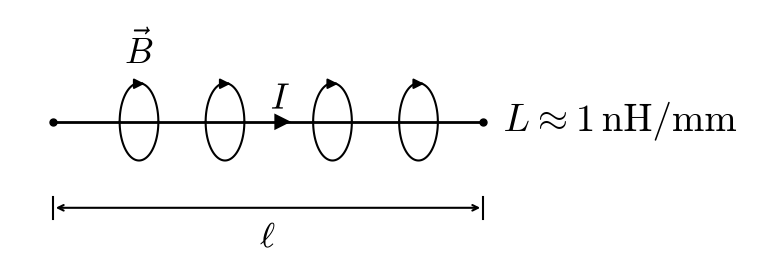

In [18]:
import numpy as np
import matplotlib
matplotlib.rcParams["svg.fonttype"] = "path"  # embed glyphs as paths so math text renders anywhere
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch

plt.rcParams.update({"text.usetex": False, "mathtext.fontset": "cm"})

scale = 0.8
fig, ax = plt.subplots(figsize=(10*scale, 3.6*scale))
ax.set_xlim(-1, 16.5)
ax.set_ylim(-3.4, 2.6)
ax.set_aspect("equal")
ax.axis("off")

x0, x1 = 0, 10          # wire ends
loop_x = [2, 4, 6.5, 8.5]  # positions of field loops
rx, ry = 0.45, 0.9      # ellipse radii (perspective view of circles around wire)

# --- field loops (drawn behind/in front of wire to look 3D) ---
t_back = np.linspace(0, np.pi, 100)           # upper half: behind the wire
t_front = np.linspace(np.pi, 2 * np.pi, 100)  # lower half: in front of the wire
for xc in loop_x:
    ax.plot(xc + rx * np.cos(t_back), ry * np.sin(t_back), "k-", lw=1.5, zorder=1)
    ax.plot(xc + rx * np.cos(t_front), ry * np.sin(t_front), "k-", lw=1.5, zorder=3)
    # arrowhead on the top of each loop showing circulation direction
    ax.add_patch(FancyArrowPatch(
        (xc + 0.07, ry-0.015), (xc + 0.13, ry-0.015),
        arrowstyle="-|>", mutation_scale=15, color="k", lw=1.5, zorder=4,
        shrinkA=0, shrinkB=0))

# --- wire ---
ax.plot([x0, x1], [0, 0], "k-", lw=2, zorder=2)
ax.plot([x0, x1], [0, 0], "ko", ms=5, zorder=5)

# --- current arrow along the wire ---
ax.add_patch(FancyArrowPatch((4.9, 0), (5.6, 0), arrowstyle="-|>",
                             mutation_scale=30, color="k", lw=0, zorder=6))
ax.text(5.25, 0.3, r"$I$", ha="center", fontsize=26)
ax.text(loop_x[0], ry + 0.25, r"$\vec{B}$", ha="center", va="bottom", fontsize=26)

# --- length dimension marker:  |<-- l -->| ---
yd = -2.0
ax.annotate("", xy=(x0, yd), xytext=(x1, yd),
            arrowprops=dict(arrowstyle="<->", lw=1.5, color="k"))
for x in (x0, x1):
    ax.plot([x, x], [yd - 0.25, yd + 0.25], "k-", lw=1.5)
ax.text((x0 + x1) / 2, yd - 0.3, r"$\ell$", ha="center", va="top", fontsize=26)

# --- inductance estimate ---
ax.text(13.2, 0, r"$L \approx 1\,\mathrm{nH/mm}$", ha="center", va="center",
        fontsize=28)

plt.tight_layout()
plt.savefig("wire_schematic.svg", bbox_inches="tight")
plt.show()